<a href="https://colab.research.google.com/github/ChanceResearcher/skills-review-pull-requests/blob/main/GNR_Task1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [48]:
import numpy as np
import random
import matplotlib.pyplot as plt

#The same seed I saw the models using.
random.seed(12345)

In [49]:
def GNR_SimulationVm(NumNodes, alpha, r_probability):
    NumNodes += 1

    #Initialize the arrays for the simulation.

    # NodeConnections[i] will be a list of nodes that node i connects to.
    NodeConnections = [[] for _ in range(NumNodes)]

    #Count of number of links per timestep / anode additions.
    Medges = np.zeros(NumNodes)
    Medges[2] = 2

    #Initial Conditions: Node 1 connected to Node 2, Node 2 connected to Node 1.
    NodeConnections[1].append(2)
    NodeConnections[2].append(1)
    Medges[1] = 2
    Medges[2] = 2

    #For each new node, randomly select a number of nodes to connect to,
    #out of a power law distribution.
    #Then, with probability r, connect to the ancestor of that node instead.

    for NodeID in range(3, NumNodes):
        # Determine possible values for 'm' (number of connections for the new node)
        # 'm' must be at least 1. Maximum 'm' can be NodeID - 1 (connections to all existing nodes).
        m_possible_values = np.arange(1, NodeID)

        # Calculate unnormalized probabilities based on the power law: P(m) ~ m^(-alpha)
        # Use the 'alpha' parameter passed to the GNR_SimulationVm function.
        unnormalized_probabilities_m = 1.0 / (m_possible_values ** alpha)

        # Normalize probabilities to sum to 1
        probabilities_m = unnormalized_probabilities_m / np.sum(unnormalized_probabilities_m)

        # Sample 'm' (the number of connections this new node will make
        m = np.random.choice(m_possible_values, p=probabilities_m)
        Medges[NodeID] = (2*m) + Medges[NodeID - 1]
        for j in range(int(m)): # Ensure m is an integer for range
            NewNode = np.random.randint(1, NodeID)
            if random.random() < r_probability:
                randomAncestor = NodeConnections[NewNode][np.random.randint(0, len(NodeConnections[NewNode]))]
                NewNode = randomAncestor

            NodeConnections[NodeID].append(NewNode)

    return Medges

Alpha used:  1.5
r used:  0.3333333333333333
Beta Expected from Theory:  1.5
Beta found from Simulation:  1.49779422848236


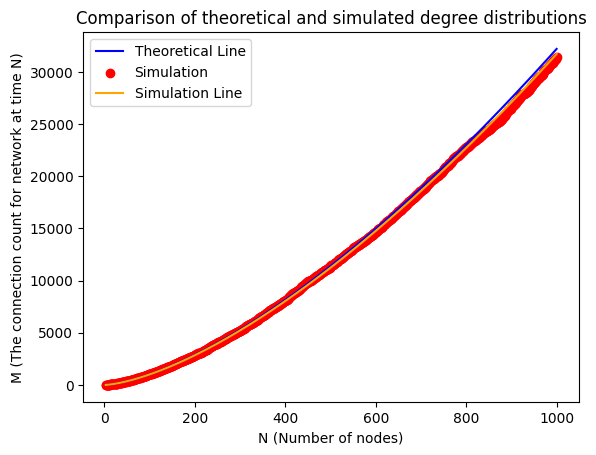

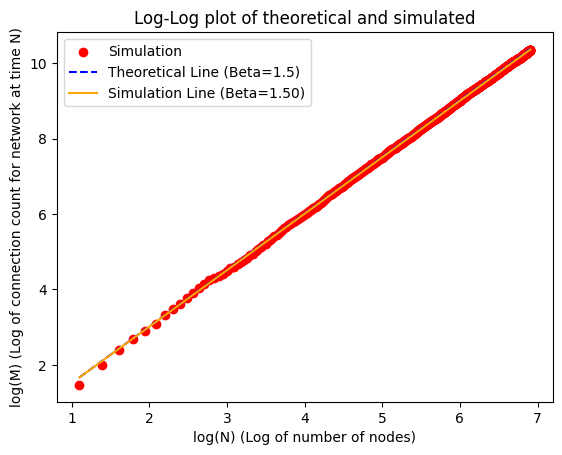

In [50]:
# Proof of model working, Part 1:
# In a log-log plot, 0 < r < (1/(3-alpha)), the slope should be equal to Beta = 2 for 0 < alpha < 1
# In a log-log plot, 0 < r < (1/(3-alpha)), the slope should be equal to Beta = 3 - alpha for 1 < alpha < 2

num_nodes_proof = 1000
alpha_proof = 1.5
r_proof = (1/(3-alpha_proof))/2
trials_proof = 30  # Increased trials for better statistical representation

# Store sum of number of edges per time for each trial to average over.
Medges_trial_all = np.zeros(num_nodes_proof + 1)

# Run the simulation for a number of trials.
for t in range(0,trials_proof):
    Medges_trial= GNR_SimulationVm(num_nodes_proof, alpha_proof, r_proof)
    Medges_trial_all += Medges_trial

# Calculate the average number of edges per timestep.
Medges = Medges_trial_all / trials_proof

# Theoretical distribution for the proof case.
# In a log-log plot, 0 < r < (1/(3-alpha)), the slope should be equal to Beta = 2 for 0 < alpha < 1
# In a log-log plot, 0 < r < (1/(3-alpha)), the slope should be equal to Beta = 3 - alpha for 1 < alpha < 2
N = np.arange(0, num_nodes_proof + 1)
N_data = N[3:]
Medges_data = Medges[3:]
# Log-Log Data Set
x_log = np.log(N_data)
y_log_sim = np.log(Medges_data) # Only log positive values

# Linear Regression of Simulation and Theory for Log-Log Plot
# Use filtered data for simulation regression
Simulation_slope,Simulation_intercept = np.polyfit(x_log, y_log_sim,1)
Sim_b = np.exp(Simulation_intercept)
Beta = Simulation_slope

# Define theoretical Beta based on comments (for 0 < alpha < 1)
if (alpha_proof < 1 and alpha_proof > 0) :
    theoretical_beta = 2
# Define theoretical Beta based on comments (for 1 < alpha < 2)
if (alpha_proof >= 1 and alpha_proof <= 2) :
    theoretical_beta = 3 - alpha_proof
else :
        print("Invalid value for alpha")
# For plotting the theoretical line, we need an intercept. We can make it pass through the first point of the simulation data.
y_theoretical = Sim_b*(N_data**theoretical_beta)
y_log_theoretical = np.log(y_theoretical)
theoretical_beta,theoretical_intercept = np.polyfit(x_log, y_log_theoretical,1)
Theoretical_b = np.exp(theoretical_intercept)

print('Alpha used: ', alpha_proof)
print('r used: ', r_proof)
print('Beta Expected from Theory: ', theoretical_beta)
print('Beta found from Simulation: ', Beta)

# Scatter Plot of Regression of Simulation and Theory
plt.figure()
# Plot theoretical line with expected beta
plt.plot(N_data, Theoretical_b*(N_data**theoretical_beta), color="blue", label="Theoretical Line")
# Plot simulation data
plt.scatter(N_data, Medges_data, color="red", label="Simulation")
# Plot simulation fit line
plt.plot(N_data, Sim_b * (N_data**Beta), color="orange", label="Simulation Line")
plt.xlabel("N (Number of nodes)")
plt.ylabel("M (The connection count for network at time N)")
plt.title("Comparison of theoretical and simulated degree distributions")
plt.legend()
plt.show()

# Log-Log Plot
plt.figure()
# Plot only positive y_sim values for the simulation scatter points
plt.scatter(x_log, y_log_sim, color="red", label="Simulation")
# Plot theoretical line with expected beta
plt.plot(x_log, theoretical_beta * x_log + theoretical_intercept, color="blue", label=f"Theoretical Line (Beta={theoretical_beta})", linestyle='--')
# Plot regression lines using the calculated slopes and intercepts for simulation
plt.plot(x_log, Simulation_slope * x_log + Simulation_intercept, color="orange", label=f"Simulation Line (Beta={Beta:.2f})")
plt.xlabel("log(N) (Log of number of nodes)")
plt.ylabel("log(M) (Log of connection count for network at time N)")
plt.title("Log-Log plot of theoretical and simulated")
plt.legend()
plt.show()
